# BhashaCore — where does a multilingual chatbot lose quality?

**SIH25104 · Language-Agnostic Chatbot.** Government chatbots answer worse in regional Indian languages. This notebook builds a small chatbot pipeline and finds the exact stage where each language loses accuracy.

The test is controlled. Every language gets **the same 900 questions** (Belebele), with the same correct option. So a lower score comes from the language, not from harder questions.

```
 user question (any language, any script)
        │
 [1] Language ID ............ char n-grams + logistic regression   → scored: label accuracy
        │
 [2] Retrieve the passage ... BM25  or  multilingual-e5            → scored: Recall@1
        │
   ┌────┴─────────────────────────┐
 [3A] Direct                    [3B] Pivot
  LLM reads the original text    NLLB translates to English         → scored: chrF
                                 then the same LLM reads English
   └────┬─────────────────────────┘
   option A / B / C / D ...................................... → scored: accuracy, gap vs English
```

| Section | What happens |
|---|---|
| 0–1 | Install, settings |
| 2 | Load Belebele (scoring data) and check that languages are paired row by row |
| 3 | Load a random sample of IndicCorp v2 (raw text) |
| 4 | **Stage 1** — train and test the language identifier |
| 5 | Token tax — how many tokens each language costs |
| 6 | **Stage 2** — retrieval with BM25 and with e5 embeddings |
| 7–8 | **Stage 3A** — the LLM answers from the original-language passage |
| 9–10 | **Stage 3B** — translate to English with NLLB, then answer |
| 11 | End to end — all stages chained, errors pass from stage to stage |
| 12–14 | Comparison report, paired statistics, failure examples |
| 15 | Write the report files |
| 16 | Chatbot demo with free-text answers |

**Hardware.** Use a GPU. The defaults (Qwen2.5-1.5B) fit an 8 GB laptop GPU. On a 24 GB GPU you can switch to Qwen2.5-7B in Section 1. The first run downloads about 6 GB of models. Every expensive result is saved in `bhashacore_outputs/cache/`, so a second run is fast.

## 0. Install

Install PyTorch 2.6 or newer with CUDA first, from [pytorch.org](https://pytorch.org/get-started/locally/). Version 2.6 matters: the NLLB weights are a `.bin` file, and recent transformers versions load `.bin` files only with torch 2.6+. Do not install `torch` with the line below, because pip can replace your CUDA build with a CPU build. Then run this cell once.

In [1]:
%pip install -q --root-user-action=ignore --disable-pip-version-check "transformers>=4.45" datasets sentencepiece sacrebleu scikit-learn scipy pandas matplotlib requests tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, math, random, string, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import sparse
from scipy.stats import binomtest
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM, AutoModelForSeq2SeqLM
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
import sacrebleu

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 140)

# Quiet library notices (errors still show)
os.environ["DISABLE_SAFETENSORS_CONVERSION"] = "1"   # stop transformers fetching a 2.5 GB safetensors copy of NLLB in the background
from huggingface_hub.utils import logging as hf_hub_logging
hf_hub_logging.set_verbosity_error()                  # hide the Hub's "set a HF_TOKEN" notice
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.cuda.memory_allocated(0) / 1e9, "GB allocated")

torch 2.11.0+cu130 | CUDA available: True
NVIDIA A30
0.0 GB allocated


## 1. Settings

Change the values in the next cell, then run all cells.

- **Languages.** Codes are Belebele / FLORES-200 codes: `<language>_<script>`. For example, `hin_Deva` is Hindi in Devanagari and `hin_Latn` is Hindi typed in English letters. The first entry is the baseline that every other language is compared with.
- **Models.** All three download from Hugging Face. None of them needs an access request.
- **`N_QUESTIONS`.** Use `200` for a fast first run. Use `None` for all 900 questions in the final report.

In [3]:
# ---------- what to test ----------
EVAL_LANGS = ["eng_Latn", "hin_Deva", "mar_Deva", "ben_Beng", "tam_Taml", "tel_Telu", "hin_Latn"]
BASELINE = "eng_Latn"

LANG_NAMES = {
    "eng_Latn": "English", "hin_Deva": "Hindi", "mar_Deva": "Marathi", "ben_Beng": "Bengali",
    "tam_Taml": "Tamil", "tel_Telu": "Telugu", "hin_Latn": "Hindi (romanized)", "ben_Latn": "Bengali (romanized)",
    "asm_Beng": "Assamese", "guj_Gujr": "Gujarati", "kan_Knda": "Kannada", "mal_Mlym": "Malayalam",
    "ory_Orya": "Odia", "pan_Guru": "Punjabi", "urd_Arab": "Urdu",
}

# Languages the language identifier learns from IndicCorp v2: IndicCorp file code -> Belebele code.
# Marathi shares the Devanagari script with Hindi, and Assamese shares the Bengali script with Bengali.
# They are here on purpose: script alone cannot separate them, so the classifier must learn the words.
# Every language in EVAL_LANGS needs its native-script entry here. Other IndicCorp codes:
# gu Gujarati, kn Kannada, ml Malayalam, or Odia, pa Punjabi, ur Urdu, ne Nepali, sa Sanskrit.
LID_LANGS = {"en": "eng_Latn", "hi": "hin_Deva", "mr": "mar_Deva", "bn": "ben_Beng",
             "as": "asm_Beng", "ta": "tam_Taml", "te": "tel_Telu"}

# NLLB needs a native-script code. It has no code for romanized Hindi, so we pass the Hindi code.
NLLB_CODE = {"hin_Latn": "hin_Deva", "ben_Latn": "ben_Beng"}   # every other code is used as it is

# ---------- models ----------
LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"        # 24 GB GPU: try "Qwen/Qwen2.5-7B-Instruct"
MT_NAME  = "facebook/nllb-200-distilled-600M"   # translator for the pivot route
EMB_NAME = "intfloat/multilingual-e5-small"     # sentence embeddings for retrieval

# ---------- size and speed ----------
N_QUESTIONS = None          # None = all 900 questions; 200 = quick first run
E2E_RETRIEVER = "e5"        # retriever used in the end-to-end run: "e5" or "bm25"
INDICCORP_LINES = 6000      # sentences kept per language
INDICCORP_CHUNKS = 40       # random places read in each IndicCorp file
INDICCORP_CHUNK_BYTES = 256 * 1024
INDICCORP_LOCAL_DIR = None  # optional: a folder with <code>.txt files (e.g. "data/indiccorp") if the download fails
LLM_BATCH, MT_BATCH, EMB_BATCH = 8, 32, 64   # lower these if you see "CUDA out of memory"
MT_BEAMS, MT_MAX_TOKENS = 1, 256
CHRF_DAMAGED = 40.0         # a passage translation below this chrF counts as "damaged"
N_FAILURE_EXAMPLES = 5      # failure examples per language in the report
SEED = 42
USE_CACHE = True            # reuse saved results; set False to recompute everything
OUT_DIR = Path("bhashacore_outputs")

In [4]:
CACHE_DIR, FIG_DIR = OUT_DIR / "cache", OUT_DIR / "figures"
for d in (OUT_DIR, CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float16
else:
    DEVICE, DTYPE = "cpu", torch.float32
MT_DTYPE = torch.float32 if DTYPE == torch.float16 else DTYPE   # NLLB can overflow in float16
QTAG = f"n{N_QUESTIONS or 'all'}"                                  # part of every cache file name
import transformers
from packaging.version import Version
DTYPE_ARG = "dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"   # renamed in 4.56
print("device:", DEVICE, "| dtype:", DTYPE, "| transformers", transformers.__version__)


def name(code):
    return LANG_NAMES.get(code, code)

def nllb_code(code):
    return NLLB_CODE.get(code, code)

missing = [l for l in EVAL_LANGS if nllb_code(l) not in LID_LANGS.values()]
assert not missing, f"Add these languages to LID_LANGS (IndicCorp code -> Belebele code): {missing}"

def slug(text):
    return re.sub(r"[^A-Za-z0-9]+", "-", str(text)).strip("-")

def chunks(items, size):
    for i in range(0, len(items), size):
        yield items[i:i + size]

def cached(key, compute):
    # Run compute() once and save its result. Later runs load the saved file.
    path = CACHE_DIR / f"{slug(key)}.pkl"
    if USE_CACHE and path.exists():
        return pd.read_pickle(path)
    result = compute()
    pd.to_pickle(result, path)
    return result

def save_fig(fig, filename):
    fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

def md_table(df, digits=1):
    # DataFrame -> Markdown table text, for the report file.
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "–" if np.isnan(v) else f"{v:.{digits}f}"
        return str(v).replace("|", "/").replace("\n", " ")
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        lines.append("| " + " | ".join([fmt(idx)] + [fmt(v) for v in row.tolist()]) + " |")
    return "\n".join(lines)

device: cuda | dtype: torch.bfloat16 | transformers 5.7.0


## 2. Belebele — the scoring data

Belebele has 900 reading questions. Each question has a short news passage, four options and one correct option. Experts translated every passage, question and option into 122 language variants. Thus row *i* in Tamil is the translation of row *i* in English.

The next cell does three things:

1. It downloads one table per language.
2. It checks that `link` and `question_number` match in every row. If they do not match, it reorders the rows by these two keys, or it stops with an error.
3. It gives every row a question id (`qid`) and every distinct passage a passage id (`pid`). These ids are the same in every language.

The **knowledge base** `KB[lang]` holds one row per passage. The retriever searches it in Section 6.

In [5]:
def load_belebele(lang):
    df = load_dataset("facebook/belebele", lang, split="test").to_pandas()
    df["answer"] = df["correct_answer_num"].astype(int) - 1          # "1".."4"  ->  0..3
    df["options"] = df[["mc_answer1", "mc_answer2", "mc_answer3", "mc_answer4"]].values.tolist()
    df["key"] = df["link"] + "#" + df["question_number"].astype(str)
    df["key"] = df["key"] + "#" + df.groupby("key").cumcount().astype(str)   # unique even if a link repeats
    return df[["key", "flores_passage", "question", "options", "answer"]]

raw = {lang: load_belebele(lang) for lang in tqdm(EVAL_LANGS, desc="Belebele")}

# Pair the rows: row i must be the same question in every language
ref_keys = raw[BASELINE]["key"].to_numpy()
for lang, df in raw.items():
    if not np.array_equal(df["key"].to_numpy(), ref_keys):
        if df["key"].is_unique and raw[BASELINE]["key"].is_unique:
            raw[lang] = df.set_index("key").loc[ref_keys].reset_index()
            print(f"{lang}: rows reordered to match {BASELINE}")
        else:
            raise ValueError(f"{lang}: cannot pair rows with {BASELINE}")
    same_answers = (raw[lang]["answer"].to_numpy() == raw[BASELINE]["answer"].to_numpy()).mean()
    print(f"{name(lang):20s} rows={len(raw[lang])}  same correct option as {BASELINE}: {same_answers:.0%}")

# Ids shared by all languages
pid_of_row = pd.factorize(raw[BASELINE]["flores_passage"])[0]
all_qids = np.arange(len(raw[BASELINE]))
qids = all_qids if N_QUESTIONS is None else np.sort(
    np.random.default_rng(SEED).choice(all_qids, N_QUESTIONS, replace=False))

B, KB = {}, {}
for lang, df in raw.items():
    df = df.assign(qid=all_qids, pid=pid_of_row)
    KB[lang] = df.drop_duplicates("pid").set_index("pid")["flores_passage"]   # all passages, even in a quick run
    B[lang] = df.set_index("qid").loc[qids]

print(f"\nquestions per language: {len(qids)} | passages in each knowledge base: {len(KB[BASELINE])}")

Belebele:   0%|          | 0/7 [00:00<?, ?it/s]

English              rows=900  same correct option as eng_Latn: 100%
hin_Deva: rows reordered to match eng_Latn
Hindi                rows=900  same correct option as eng_Latn: 100%
mar_Deva: rows reordered to match eng_Latn
Marathi              rows=900  same correct option as eng_Latn: 100%
ben_Beng: rows reordered to match eng_Latn
Bengali              rows=900  same correct option as eng_Latn: 100%
tam_Taml: rows reordered to match eng_Latn
Tamil                rows=900  same correct option as eng_Latn: 100%
tel_Telu: rows reordered to match eng_Latn
Telugu               rows=900  same correct option as eng_Latn: 100%
Hindi (romanized)    rows=900  same correct option as eng_Latn: 100%

questions per language: 900 | passages in each knowledge base: 488


In [6]:
# One question, in every language. The passage is cut to 160 characters for display.
q = qids[0]
pd.DataFrame([{
    "language": name(lang),
    "passage (start)": B[lang].loc[q, "flores_passage"][:160] + " ...",
    "question": B[lang].loc[q, "question"],
    "correct option": B[lang].loc[q, "options"][B[lang].loc[q, "answer"]],
} for lang in EVAL_LANGS]).set_index("language")

,passage (start),question,correct option
language,,,
English,Make sure your hand is as relaxed as possible while still hitting all the notes correctly - also try not to make much extraneous motion ...,"According to the passage, what would not be considered an accurate tip for successfully playing the accordion?","For additional volume, increase the force with which you hit the keys"
Hindi,"सुनिश्चित करें कि आपका हाथ सभी नोट्स को सही से बजाते हुए भी जितना हो सके, उतना स्थिर है - यह भी प्रयास करें कि आपकी उंगलियाँं अत्यधिक गत...","गद्यांश के अनुसार, संगीत के लिए अक्कादियन को सटीक रूप से पुनर्स्थापित करने के लिए वास्तव में क्या संभव नहीं है?",अधिक मात्रा में उत्पन्न करने के लिए कुंजियों को अधिक बल के साथ दबाया जाना चाहिए
Marathi,"सर्व नोट्स योग्यरित्या दाबताना तुमचा हात शक्य तितका हलका असल्याचे सुनिश्चित करा - बोटांची जास्त हालचाल करू नका. अशाप्रकारे, तुम्ही स्वतः...","परिच्छेदानुसार, अकॉर्डियन यशस्वीरित्या वाजवण्यासाठी कोणती टीप अचूक मानली जाणार नाही?","अतिरिक्त व्हॉल्यूमसाठी, तुम्ही ज्या बळाने कीज दाबता त्यात वाढ करा"
Bengali,"নোটগুলি লেখার সময় খেয়াল রাখবেন আপনার হাত যেন আরামে থাকে, এ ছাড়াও আপনার আঙুলগুলি বাইরের দিকে না নাড়ানোর চেষ্টা করবেন। এইভাবে, আপনি ধীরে...","অনুচ্ছেদ অনুযায়ী, সুন্দরভাবে অ্যাকর্ডিয়ন বাজানোর জন্য কোনটি সঠিক পরামর্শ হিসাবে বিবেচিত হবে না?","বেশি আওয়াজ পাওয়ার জন্য, বাদ্যযন্ত্রের চাবি আরও জোরে-জোরে টিপতে হবে"
Tamil,"அனைத்து சுரங்களையும் சரியாக வாசிக்கும் போது உன் கை முடிந்தவரை சௌகரியமாக இருப்பதை உறுதி செய்து கொள்ளவும், மேலும், விரல்களால் அதிக தேவையற்...","கொடுக்கப்பட்டிருக்கும் இந்த பத்தியில், சுரங்களை துல்லியமாக வாசிப்பதற்கான சரியான உதவிக் குறிப்பு இல்லை எனக் கருதப்படுவது எது?","அதிக அளவு ஒலியினை ஏற்படுத்த, விசைகளை அதிக அளவு ஆற்றலுடன் அழுத்த வேண்டும்"
Telugu,అన్ని నోట్స్ ని సరిగ్గా కొట్టేటప్పుడు మీ చేయి సాధ్యమైనంత వరకు రిలాక్స్ గా ఉండేలా చూసుకోండి- అదేవిధంగా మీ వేళ్లతో ఎక్కువ ఎక్స్ ట్రానియస్ ...,"పద్దతి ప్రకారం, అకార్డియన్‌ను చక్కగా వాయించడానికి ఖచ్చితమైన చిట్కాగా దేనిని చూడరు?","సౌండ్ ఎక్కువగా కావాలకున్నప్పుడు, మీరు కీలను గట్టిగా నొక్కడానిని"
Hindi (romanized),"Sunishchit karein ki aapka haath sabhi notes ko sahi se bajaate hue bhi jitna ho sake, utna sthir hai - yeh bhi prayaas karein ki aapki ...","Passage ke hisab se, accordion ache se bajaane ki kaun si sabse sahi tip nhi kehlayegi?",Zyada aawaaz ke liye kunji ko zyada dabaav ke sath dabaayein


## 3. IndicCorp v2 — raw text for each language

IndicCorp v2 (AI4Bharat) holds billions of sentences from Indian news and web pages, one text file per language. It has **no questions and no answers**, so it cannot score a chatbot. We use it for two jobs:

- to train the language identifier (Section 4), and
- to measure how many tokens each language needs (Section 5).

The files are large: 1 GB to 80 GB each. We do not download them. We read 40 small pieces (256 KB each) at random places with HTTP *range requests*, and keep complete sentences only. Random places give a fairer mix of topics than the first lines of a file, which come from a few websites only.

If the download fails, download any part of a file by hand from the [dataset page](https://huggingface.co/datasets/ai4bharat/IndicCorpV2), save it as `<folder>/<code>.txt` (for example `data/indiccorp/ta.txt`), and set `INDICCORP_LOCAL_DIR` in Section 1.

In [7]:
INDICCORP_URL = os.environ.get("HF_ENDPOINT", "https://huggingface.co") + \
    "/datasets/ai4bharat/IndicCorpV2/resolve/main/data/{}"

def indiccorp_filename(code):
    return "hi-1.txt" if code == "hi" else f"{code}.txt"     # Hindi is split into 3 files

RAW = {"Accept-Encoding": "identity"}   # ask for plain bytes: a byte range of a gzip stream cannot be decoded

def remote_size(url):
    with requests.get(url, headers={**RAW, "Range": "bytes=0-0"}, stream=True, timeout=60) as r:
        r.raise_for_status()
        return int(r.headers["Content-Range"].split("/")[-1])

def fetch_range(url, start, n_bytes):
    # Download bytes [start, start + n_bytes) of a remote file.
    with requests.get(url, headers={**RAW, "Range": f"bytes={start}-{start + n_bytes - 1}"}, stream=True, timeout=120) as r:
        r.raise_for_status()
        if r.status_code != 206:     # the server ignored the range: stop instead of downloading 20 GB
            raise RuntimeError("The server does not support range requests")
        return r.content

def random_lines(read, size, rng):
    # Read INDICCORP_CHUNKS pieces at random offsets; keep only the complete lines.
    lines = []
    for _ in range(INDICCORP_CHUNKS):
        start = rng.randrange(0, max(1, size - INDICCORP_CHUNK_BYTES))
        text = read(start, INDICCORP_CHUNK_BYTES).decode("utf-8", errors="ignore")
        parts = text.split("\n")
        lines += parts[1:-1] if start > 0 else parts[:-1]       # first and last parts are cut lines
    return lines

def sample_indiccorp(code):
    cache = CACHE_DIR / f"indiccorp_{code}_{INDICCORP_LINES}.txt"
    if cache.exists():
        return cache.read_text(encoding="utf-8").split("\n")
    rng = random.Random(f"{SEED}-{code}")
    local = Path(INDICCORP_LOCAL_DIR) / f"{code}.txt" if INDICCORP_LOCAL_DIR else None
    if local is not None and local.exists():
        with open(local, "rb") as f:
            def read(start, n):
                f.seek(start)
                return f.read(n)
            lines = random_lines(read, local.stat().st_size, rng)
    else:
        url = INDICCORP_URL.format(indiccorp_filename(code))
        lines = random_lines(lambda start, n: fetch_range(url, start, n), remote_size(url), rng)
    seen, kept = set(), []
    for line in lines:
        line = line.strip()
        if len(line.split()) >= 4 and line not in seen:   # drop headings, very short lines and repeats
            seen.add(line)
            kept.append(line)
    rng.shuffle(kept)
    kept = kept[:INDICCORP_LINES]
    cache.write_text("\n".join(kept), encoding="utf-8")
    return kept

corpus = {code: sample_indiccorp(code) for code in tqdm(LID_LANGS, desc="IndicCorp")}
pd.DataFrame([{
    "IndicCorp code": code, "language": name(LID_LANGS[code]), "sentences": len(lines),
    "avg words per sentence": np.mean([len(l.split()) for l in lines]), "example": lines[0][:90],
} for code, lines in corpus.items()]).set_index("IndicCorp code").round(1)

IndicCorp:   0%|          | 0/7 [00:00<?, ?it/s]

,language,sentences,avg words per sentence,example
IndicCorp code,,,,
en,English,6000,41.2,"Loud noise doesn't just lead to hearing problems. ""Being in a noisy situation may force yo"
hi,Hindi,6000,55.0,ज्वालामुखी/चामुंडा— प्रसिद्ध पंजाबी गायक गुरदास मान परिवार सहित श्रीचामुंडा व ज्वालाजी मंद
mr,Marathi,6000,40.9,आता स्वतः चालवा ओला कार आणखी वाचा
bn,Bengali,6000,48.4,হারাবার খাতাটা নগ্ন নয় ততটা যতটা হবার কথা ছিল হয়তোবা;হয়তোবা না।
as,Assamese,6000,40.7,শুকুৰবাৰে কেন্দ্ৰীয় বিত্তমন্ত্ৰী নিৰ্মলা সীতাৰমণে দাখিল কৰা কেন্দ্ৰীয় বাজেট-২০১৯ত অসমকে ধৰ
ta,Tamil,6000,37.5,பாஜவின் பிரச்சாரத்தை எதிர்க்க கெஜ்ரிவால் முஸ்லிம்களுக்கு ஆதரவாளராக சித்தரிக்கப்பட்டார். அவ
te,Telugu,6000,36.7,తాజాగా బ‌య‌ట‌కొచ్చిన ఫొటోల్లో కండలు పెంచి సరికొత్తగా క‌నిపిస్తున్నాడు రామ్ పోతినేని. ఈయనను


## 4. Stage 1 — Language identification

**Job.** Read the user's message and name its language. Later stages need this label: the translator needs the source language, and the bot must choose which knowledge base to search.

**Model.** Two simple parts:

1. **TF-IDF over character n-grams.** The text is cut into pieces of 1 to 3 characters inside each word. For example, `नमस्ते` gives `न`, `नम`, `नमस`, `म`, ... Each piece becomes one feature. TF-IDF gives a high weight to pieces that are frequent in this text but rare in other texts.
2. **Logistic regression.** It learns one weight per piece and per language, then picks the language with the highest score (softmax over 7 classes).

**Why characters, not words?** Character pieces work for words the model never saw, and for spelling variants. Script alone is not enough: Hindi and Marathi both use Devanagari, and Bengali and Assamese both use the Bengali script.

**Test.** We train on IndicCorp sentences. Then we test on Belebele *questions*. These are shorter and come from a different source, like real chat messages. Romanized Hindi is a hard case on purpose: IndicCorp has no romanized text, so the model never saw it.

In [8]:
texts = [line for code in LID_LANGS for line in corpus[code]]
labels = [code for code in LID_LANGS for _ in corpus[code]]
X_train, X_val, y_train, y_val = train_test_split(texts, labels, test_size=0.2, random_state=SEED, stratify=labels)

lid = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), max_features=100_000, sublinear_tf=True),
    LogisticRegression(max_iter=1000, C=10.0),
)
lid.fit(X_train, y_train)
print(f"accuracy on held-out IndicCorp sentences: {accuracy_score(y_val, lid.predict(X_val)):.1%}")

# What did it learn? The 8 character pieces with the highest weight for each language.
vec, clf = lid.named_steps["tfidfvectorizer"], lid.named_steps["logisticregression"]
features = vec.get_feature_names_out()
for i, code in enumerate(clf.classes_):
    top = features[np.argsort(clf.coef_[i])[-8:][::-1]]
    print(f"{code:3s}", "  ".join(repr(t) for t in top))

accuracy on held-out IndicCorp sentences: 99.9%
as  'ৰ'  'ৰ '  'ৱ'  'াৰ'  '্ৰ'  'ৰি'  'ত '  'ৰা'
bn  'র'  'র '  'ে'  'ার'  'া'  'ে '  'ের'  'ের '
en  'a'  'e'  's'  'o'  't'  'i'  'n'  'r'
hi  ' क'  'ं '  'के '  'ै'  'र '  'क'  'ें '  'ें'
mr  'ण'  'ळ'  'च'  'त'  '्या'  'ा'  'ां'  'ल'
ta  '்'  'ி'  'க'  'ு'  'த'  '் '  'ர'  'ப'
te  '్'  'ి'  'ా'  'ర'  'ు'  'ల'  'న'  'ం'


In [9]:
# Test on Belebele questions (short texts from a different source)
belebele_to_lid = {bb: code for code, bb in LID_LANGS.items()}
def true_lid_code(lang):
    return belebele_to_lid.get(lang, belebele_to_lid.get(nllb_code(lang)))   # romanized Hindi is still Hindi

LID_PRED, lid_acc = {}, {}
for lang in EVAL_LANGS:
    LID_PRED[lang] = pd.Series(lid.predict(B[lang]["question"].tolist()), index=B[lang].index)
    lid_acc[lang] = 100 * (LID_PRED[lang] == true_lid_code(lang)).mean()

# Shorter messages are harder: keep only the first k words of each question
short = {}
for k in (1, 2, 3, 5):
    short[f"first {k} word{'s' if k > 1 else ''}"] = {
        name(lang): 100 * (lid.predict([" ".join(q.split()[:k]) for q in B[lang]["question"]]) == true_lid_code(lang)).mean()
        for lang in EVAL_LANGS}
short["full question"] = {name(lang): lid_acc[lang] for lang in EVAL_LANGS}
lid_short_df = pd.DataFrame(short).round(1)
lid_short_df.index.name = "language"
lid_short_df

,first 1 word,first 2 words,first 3 words,first 5 words,full question
language,,,,,
English,100.0,100.0,100.0,100.0,100.0
Hindi,37.4,87.4,94.1,96.7,99.9
Marathi,82.2,90.3,94.7,97.8,99.7
Bengali,92.1,94.6,96.8,99.4,99.8
Tamil,98.1,99.2,99.6,100.0,100.0
Telugu,96.1,99.4,99.7,99.9,99.9
Hindi (romanized),0.2,0.0,0.0,0.0,0.0


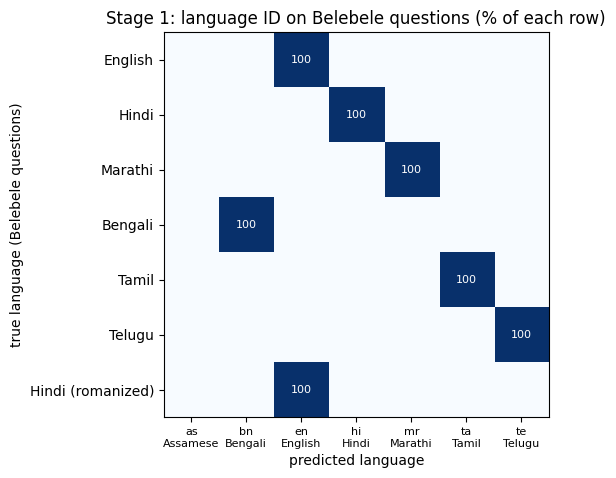

In [10]:
classes = list(clf.classes_)
cm = pd.DataFrame(0.0, index=[name(l) for l in EVAL_LANGS], columns=classes)
for lang in EVAL_LANGS:
    counts = LID_PRED[lang].value_counts(normalize=True)
    for code, share in counts.items():
        cm.loc[name(lang), code] = 100 * share

fig, ax = plt.subplots(figsize=(7, 0.5 * len(EVAL_LANGS) + 1.5))
ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(classes)), [f"{c}\n{name(LID_LANGS[c])}" for c in classes], fontsize=8)
ax.set_yticks(range(len(cm)), cm.index)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        if v >= 0.5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax.set_xlabel("predicted language"); ax.set_ylabel("true language (Belebele questions)")
ax.set_title("Stage 1: language ID on Belebele questions (% of each row)")
save_fig(fig, "1_langid_confusion.png")

## 5. Token tax — how many tokens does each language cost?

A language model does not read words. It reads **tokens**, pieces made by its tokenizer. Tokenizers learn their pieces mostly from English text. So an Indian-language word is often cut into many small pieces.

We measure this in two ways:

- **Fertility** = tokens ÷ words, on IndicCorp sentences. English is near 1.3. A value of 5 means an average word becomes 5 tokens.
- **Token tax** = tokens for a Belebele passage ÷ tokens for the same passage in English. Belebele is parallel, so both texts carry the same meaning. A token tax of 3.0 means the model must read 3 times more tokens for the same content.

More tokens means a longer input, more compute, and often lower accuracy. Section 14 checks if the token tax goes with the accuracy drop.

,LLM,translator (NLLB),retriever (e5)
language (IndicCorp),,,
English,1.37,1.46,1.45
Hindi,4.69,1.46,1.44
Marathi,6.58,2.08,1.93
Bengali,7.04,2.15,2.11
Assamese,7.73,2.24,2.96
Tamil,9.98,2.64,2.44
Telugu,11.72,2.65,2.37


,LLM,translator (NLLB),retriever (e5)
language (Belebele),,,
English,1.00,1.00,1.00
Hindi,4.45,1.22,1.25
Marathi,4.63,1.27,1.23
Bengali,5.08,1.29,1.39
Tamil,6.14,1.42,1.36
Telugu,7.04,1.35,1.34
Hindi (romanized),1.93,1.45,1.50


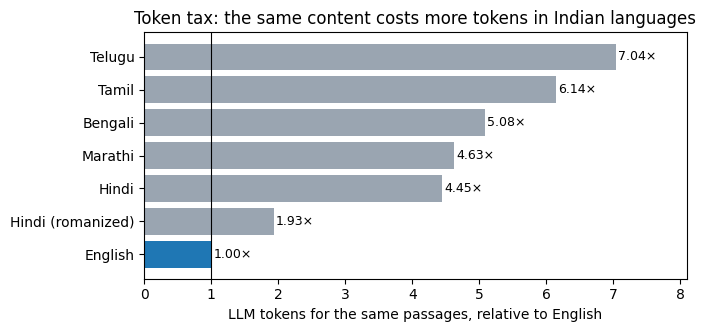

In [11]:
TOKENIZERS = {
    "LLM": AutoTokenizer.from_pretrained(LLM_NAME),
    "translator (NLLB)": AutoTokenizer.from_pretrained(MT_NAME),
    "retriever (e5)": AutoTokenizer.from_pretrained(EMB_NAME),
}

def n_tokens(tok, texts):
    # verbose=False: we only count tokens, so the "longer than the maximum length" notice does not apply
    return np.array([len(ids) for ids in tok(list(texts), add_special_tokens=False, verbose=False)["input_ids"]])

fert = pd.DataFrame({tname: {name(LID_LANGS[code]): n_tokens(tok, corpus[code][:1000]).sum()
                                                  / sum(len(l.split()) for l in corpus[code][:1000])
                             for code in LID_LANGS}
                     for tname, tok in TOKENIZERS.items()}).round(2)
fert.index.name = "language (IndicCorp)"

english_tokens = {tname: n_tokens(tok, KB[BASELINE]).sum() for tname, tok in TOKENIZERS.items()}
token_tax = pd.DataFrame({tname: {name(lang): n_tokens(tok, KB[lang]).sum() / english_tokens[tname] for lang in EVAL_LANGS}
                          for tname, tok in TOKENIZERS.items()}).round(2)
token_tax.index.name = "language (Belebele)"
display(fert)
display(token_tax)

fig, ax = plt.subplots(figsize=(7, 3.2))
order = token_tax["LLM"].sort_values()
ax.barh(order.index, order.values, color=["#1f77b4" if l == name(BASELINE) else "#9aa5b1" for l in order.index])
for i, v in enumerate(order.values):
    ax.text(v + 0.03, i, f"{v:.2f}×", va="center", fontsize=9)
ax.axvline(1, color="black", lw=0.8)
ax.set_xlim(0, order.max() * 1.15)                        # room for the value labels
ax.set_xlabel("LLM tokens for the same passages, relative to English")
ax.set_title("Token tax: the same content costs more tokens in Indian languages")
save_fig(fig, "2_token_tax.png")

## 6. Stage 2 — Retrieval: find the right passage

**Job.** The user asks a question. The bot must find the passage that holds the answer. Here the knowledge base is the 488 Belebele passages in the user's language, and the right answer is the passage that the question was written for.

**Method 1 — BM25** (classic search engine scoring). A passage scores high when it contains the query words, especially rare words. The score for query *q* and passage *d* is

$$\text{BM25}(q, d) = \sum_{w \in q} \text{idf}(w)\cdot \frac{tf(w,d)\,(k_1+1)}{tf(w,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}$$

`tf` = how often the word occurs in the passage, `idf` = how rare the word is across passages, |d| = passage length. We write it ourselves below; it is one sparse matrix product.

**Method 2 — multilingual-e5-small** (dense embeddings). This is a 12-layer BERT-style encoder. It turns a text into one vector of 384 numbers: we average the output vectors of all tokens (mean pooling) and normalize the result. It was trained so that a question and its matching passage get vectors that point the same way. The score is the cosine similarity. The model needs the prefixes `query: ` and `passage: `.

**Why both?** BM25 matches exact word forms. Tamil and Telugu add many endings to one word root, so the exact form in the question often differs from the form in the passage. Dense vectors can match meaning instead of form.

**Metric. Recall@1** = the share of questions whose right passage is ranked first. Recall@5 = right passage in the top 5.

In [12]:
PUNCT = "".join(set(string.punctuation) | set("।॥“”‘’…–—«»"))

def words(text):
    # lowercase, split on spaces, strip punctuation from both ends of each word
    return [w for w in (t.strip(PUNCT) for t in text.lower().split()) if w]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.vec = CountVectorizer(analyzer=words)
        tf = self.vec.fit_transform(docs).tocoo().astype(np.float32)        # passages x vocabulary
        n_docs = tf.shape[0]
        df = np.bincount(tf.col, minlength=tf.shape[1])                     # passages that contain each word
        idf = np.log((n_docs - df + 0.5) / (df + 0.5) + 1.0)
        doc_len = np.asarray(tf.tocsr().sum(axis=1)).ravel()
        denom = tf.data + k1 * (1 - b + b * doc_len[tf.row] / doc_len.mean())
        weight = idf[tf.col] * tf.data * (k1 + 1) / denom                   # BM25 weight of each (passage, word)
        self.W = sparse.csr_matrix((weight, (tf.row, tf.col)), shape=tf.shape)

    def scores(self, queries):
        q = self.vec.transform(queries)
        q.data[:] = 1                                                       # each query word counts once
        return (q @ self.W.T).toarray()                                      # queries x passages


emb_tok = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).to(DEVICE).eval()

@torch.no_grad()
def embed(texts, prefix):
    vecs = []
    for batch in chunks(list(texts), EMB_BATCH):
        enc = emb_tok([prefix + t for t in batch], padding=True, truncation=True, max_length=512, return_tensors="pt").to(DEVICE)
        hidden = emb_model(**enc).last_hidden_state                         # (batch, tokens, 384)
        mask = enc["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        mean = (hidden * mask).sum(dim=1) / mask.sum(dim=1)                  # average over real tokens only
        vecs.append(F.normalize(mean.float(), dim=-1).cpu())
    return torch.cat(vecs).numpy()

class DenseIndex:
    def __init__(self, docs):
        self.D = embed(docs, "passage: ")
    def scores(self, queries):
        return embed(queries, "query: ") @ self.D.T                           # cosine similarity


INDEXES = {}
def retrieve(method, kb_lang, queries, k=5):
    # Return the ids of the k best passages from KB[kb_lang], best first.
    if (method, kb_lang) not in INDEXES:
        docs = KB[kb_lang].tolist()
        INDEXES[(method, kb_lang)] = BM25(docs) if method == "bm25" else DenseIndex(docs)
    scores = INDEXES[(method, kb_lang)].scores(list(queries))
    return KB[kb_lang].index.to_numpy()[np.argsort(-scores, axis=1)[:, :k]]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Recall@1       Recall@5      
method                bm25    e5     bm25    e5
language                                       
English               80.6  90.7     89.6  97.2
Hindi                 61.8  78.9     78.2  90.3
Marathi               45.9  76.3     63.1  88.4
Bengali               56.3  74.3     71.0  89.2
Tamil                 58.4  73.0     72.4  87.7
Telugu                51.3  65.7     67.3  84.8
Hindi (romanized)     67.9  43.0     80.6  58.8

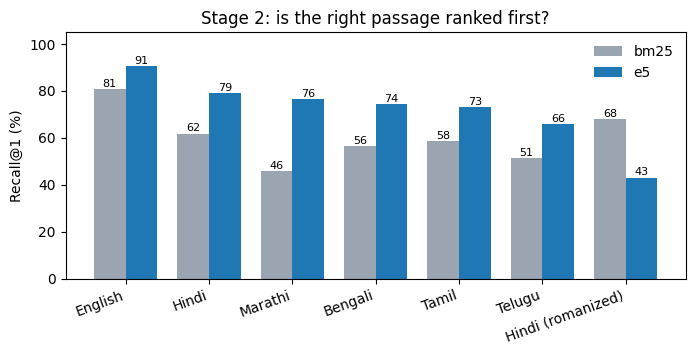

In [13]:
RET_TOP, rows = {}, []
for lang in EVAL_LANGS:
    gold = B[lang]["pid"].to_numpy()
    for method in ("bm25", "e5"):
        top = cached(f"retrieval_{method}_{slug(EMB_NAME) if method == 'e5' else ''}_{lang}_{QTAG}",
                     lambda: retrieve(method, lang, B[lang]["question"]))
        RET_TOP[(method, lang)] = top
        rows.append({"language": name(lang), "method": method,
                     "Recall@1": 100 * (top[:, 0] == gold).mean(),
                     "Recall@5": 100 * (top == gold[:, None]).any(axis=1).mean()})
ret_df = pd.DataFrame(rows)
ret_table = ret_df.pivot(index="language", columns="method", values=["Recall@1", "Recall@5"]).round(1)
ret_table = ret_table.loc[[name(l) for l in EVAL_LANGS]]
display(ret_table)

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(EVAL_LANGS))
for i, (method, color) in enumerate([("bm25", "#9aa5b1"), ("e5", "#1f77b4")]):
    vals = ret_table[("Recall@1", method)].to_numpy()
    ax.bar(x + (i - 0.5) * 0.38, vals, width=0.38, color=color, label=method)
    for xi, v in zip(x, vals):
        ax.text(xi + (i - 0.5) * 0.38, v + 1, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, [name(l) for l in EVAL_LANGS], rotation=20, ha="right")
ax.set_ylim(0, 105); ax.set_ylabel("Recall@1 (%)")
ax.set_title("Stage 2: is the right passage ranked first?")
ax.legend(frameon=False)
save_fig(fig, "3_retrieval.png")

## 7. Stage 3 — The answering model

**Model.** Qwen2.5-Instruct, a decoder-only transformer (the same family as GPT). It reads the prompt from left to right and predicts the next token.

**Prompt.** The instruction is in English for every language. Only the passage, the question and the options change language. Thus the comparison changes one thing only.

**How we read its answer: option scoring.** We do not let the model write freely and then parse the text. We run the prompt once and look at the probability the model gives to the next token being `A`, `B`, `C` or `D`. We keep these 4 numbers, apply softmax over them, and pick the highest. This is the method from the Belebele paper. It has three benefits:

- one forward pass per question (fast),
- no parsing errors (the answer is always one of 4 options),
- a confidence value for free (the winning probability).

**A detail for batches.** Prompts have different lengths, so we pad them. We pad on the **left**. Then the last position of every row is the real last token, and `[:, -1]` gives the next-token scores for all rows at once. We also apply the output layer (`lm_head`) to that last position only. The full output would be batch × length × 151,000 numbers, which wastes gigabytes of memory.

In [14]:
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm_tok.padding_side = "left"
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, **{DTYPE_ARG: DTYPE}).to(DEVICE).eval()

LETTERS = ["A", "B", "C", "D"]
USE_CHAT = llm_tok.chat_template is not None                  # instruct models have a chat template
SYSTEM = "You are a helpful assistant for citizens. Answer only from the given passage."

def wrap(user_text):
    if USE_CHAT:
        messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
        return llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return user_text + "\nAnswer:"

def build_prompt(passage, question, options):
    lines = [f"Passage:\n{passage}", f"Question:\n{question}",
             "\n".join(f"{letter}. {opt}" for letter, opt in zip(LETTERS, options)),
             "Reply with only the letter of the correct option: A, B, C or D."]
    return wrap("\n\n".join(lines))

# Token id of each answer letter. Base models (no chat template) put a space before the letter.
LABEL_IDS = [llm_tok.encode(l if USE_CHAT else " " + l, add_special_tokens=False)[0] for l in LETTERS]
assert len(set(LABEL_IDS)) == 4, "the 4 letters must be 4 different tokens"

@torch.no_grad()
def score_prompts(prompts, desc=""):
    # Return (probabilities over A-D for each prompt, prompt length in tokens).
    probs = np.zeros((len(prompts), 4), dtype=np.float32)
    lengths = np.zeros(len(prompts), dtype=int)
    order = np.argsort([-len(p) for p in prompts])            # longest first: an out-of-memory error shows at once
    for batch_idx in tqdm(list(chunks(order, LLM_BATCH)), desc=desc, leave=False):
        enc = llm_tok([prompts[i] for i in batch_idx], return_tensors="pt", padding=True,
                      add_special_tokens=not USE_CHAT).to(DEVICE)
        positions = (enc["attention_mask"].cumsum(-1) - 1).clamp(min=0)        # real positions despite left padding
        hidden = llm.base_model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                                position_ids=positions, use_cache=False).last_hidden_state[:, -1, :]   # last token
        logits = llm.get_output_embeddings()(hidden).float()                   # lm_head on the last position only
        probs[batch_idx] = torch.softmax(logits[:, LABEL_IDS], dim=-1).cpu().numpy()
        lengths[batch_idx] = enc["attention_mask"].sum(dim=1).cpu().numpy()
    return probs, lengths

RESULTS = {}     # (setting, lang) -> one row per question: pred, conf, p_gold, n_tokens, correct

def run_llm(setting, lang, passages, questions, options):
    def compute():
        prompts = [build_prompt(p, q, o) for p, q, o in zip(passages, questions, options)]
        return score_prompts(prompts, desc=f"{setting} | {name(lang)}")
    probs, lengths = cached(f"llm_{slug(LLM_NAME)}_{setting}_{lang}_{QTAG}", compute)
    gold = B[lang]["answer"].to_numpy()
    res = pd.DataFrame({"pred": probs.argmax(1), "conf": probs.max(1),
                        "p_gold": probs[np.arange(len(gold)), gold], "n_tokens": lengths}, index=B[lang].index)
    res["correct"] = res["pred"].to_numpy() == gold
    RESULTS[(setting, lang)] = res
    return res

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [15]:
# Sanity check on one English question: see the exact prompt and the 4 probabilities
b = B[BASELINE].iloc[0]
example_prompt = build_prompt(b["flores_passage"], b["question"], b["options"])
print(example_prompt)
p, n = score_prompts([example_prompt])
print("probabilities:", dict(zip(LETTERS, p[0].round(3))), "| correct:", LETTERS[b["answer"]], "| prompt tokens:", n[0])

<|im_start|>system
You are a helpful assistant for citizens. Answer only from the given passage.<|im_end|>
<|im_start|>user
Passage:
Make sure your hand is as relaxed as possible while still hitting all the notes correctly - also try not to make much extraneous motion with your fingers. This way, you will tire yourself out as little as possible. Remember there's no need to hit the keys with a lot of force for extra volume like on the piano. On the accordion, to get extra volume, you use the bellows with more pressure or speed.

Question:
According to the passage, what would not be considered an accurate tip for successfully playing the accordion?

A. For additional volume, increase the force with which you hit the keys
B. Keep unnecessary movement to a minimum in order to preserve your stamina
C. Be mindful of hitting the notes while maintaining a relaxed hand
D. Increase the speed with which you operate the bellows to achieve extra volume

Reply with only the letter of the correct opt

  0%|          | 0/1 [00:00<?, ?it/s]

probabilities: {'A': np.float32(1.0), 'B': np.float32(0.0), 'C': np.float32(0.0), 'D': np.float32(0.0)} | correct: A | prompt tokens: 217


## 8. Stage 3A — Direct route, with the correct passage

The model gets the correct passage, the question and the options, all in the test language. This isolates the **reading** step: retrieval cannot fail here, because we give the right passage.

Chance level is 25% (4 options).

In [16]:
for lang in EVAL_LANGS:
    b = B[lang]
    run_llm("direct_gold", lang, b["flores_passage"], b["question"], b["options"])

pd.DataFrame({name(lang): {"accuracy (%)": 100 * RESULTS[("direct_gold", lang)]["correct"].mean(),
                           "avg prompt tokens": RESULTS[("direct_gold", lang)]["n_tokens"].mean()}
              for lang in EVAL_LANGS}).T.round(1)

,accuracy (%),avg prompt tokens
English,79.8,197.9
Hindi,46.9,665.9
Marathi,38.4,685.3
Bengali,44.3,758.6
Tamil,38.3,895.7
Telugu,35.3,1029.8
Hindi (romanized),44.6,317.1


## 9. Translation to English with NLLB

**Model.** NLLB-200 distilled 600M (Meta). It is an encoder-decoder transformer, the same design as the original *Attention Is All You Need* model. The encoder reads the source sentence. The decoder writes the English sentence one token at a time. A language tag tells it the source language, and the first output token (`eng_Latn`) tells it the target language.

**Sentence by sentence.** NLLB was trained on single sentences. Long inputs can make it skip text. So we cut each passage at `.`, `?`, `!` and `।`, translate the sentences, and join them again.

**Translation quality: chrF.** Belebele gives us the real English passage, so we can score the machine translation against it. chrF compares character n-grams of the two texts (like an F1 score over character pieces). It is 0–100; higher is better. chrF works better than word overlap for languages with long words.

All translations are saved in a cache file, so each sentence is translated only once.

In [17]:
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_NAME, **{DTYPE_ARG: MT_DTYPE}).to(DEVICE).eval()
MT_TOKS = {}
def mt_tokenizer(src):
    # One tokenizer per source language: it puts the source-language tag in front of every input.
    if src not in MT_TOKS:
        MT_TOKS[src] = AutoTokenizer.from_pretrained(MT_NAME, src_lang=src)
    return MT_TOKS[src]

TCACHE_PATH = CACHE_DIR / f"translations_{slug(MT_NAME)}_beams{MT_BEAMS}.json"
TCACHE = json.loads(TCACHE_PATH.read_text(encoding="utf-8")) if (USE_CACHE and TCACHE_PATH.exists()) else {}

@torch.no_grad()
def translate(texts, src, tgt="eng_Latn"):
    texts = list(texts)
    if src == tgt:
        return texts
    key = lambda t: f"{src}>{tgt}|{t}"
    todo = sorted({t for t in texts if key(t) not in TCACHE}, key=len, reverse=True)
    if todo:
        mt_tok = mt_tokenizer(src)                              # adds the source-language tag
        tgt_id = mt_tok.convert_tokens_to_ids(tgt)              # forced first output token = target language
        for batch in tqdm(list(chunks(todo, MT_BATCH)), desc=f"translate {src} -> {tgt}", leave=False):
            enc = mt_tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=MT_MAX_TOKENS).to(DEVICE)
            # max_length, not max_new_tokens: NLLB's own config already sets max_length, and setting both warns
            out = mt_model.generate(**enc, forced_bos_token_id=tgt_id, num_beams=MT_BEAMS, max_length=MT_MAX_TOKENS)
            for t, o in zip(batch, mt_tok.batch_decode(out, skip_special_tokens=True)):
                TCACHE[key(t)] = o
        TCACHE_PATH.write_text(json.dumps(TCACHE, ensure_ascii=False), encoding="utf-8")
    return [TCACHE[key(t)] for t in texts]

SENTENCE_END = re.compile(r"(?<=[.!?।॥])\s+")

def translate_passages(passages, src, tgt="eng_Latn"):
    # Translate long texts sentence by sentence, then join the sentences again.
    if src == tgt:
        return list(passages)
    split = [[s for s in SENTENCE_END.split(p.strip()) if s] for p in passages]
    flat = translate([s for sents in split for s in sents], src, tgt)
    out, i = [], 0
    for sents in split:
        out.append(" ".join(flat[i:i + len(sents)]))
        i += len(sents)
    return out

def translate_by_source(texts, sources, fn=translate):
    # Translate each text from its own source language (a Belebele code) to English.
    texts, sources = list(texts), list(sources)
    out = list(texts)
    for src in set(sources):
        idx = [i for i, s in enumerate(sources) if s == src]
        for i, t in zip(idx, fn([texts[i] for i in idx], nllb_code(src))):
            out[i] = t
    return out

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

In [18]:
PIVOT, chrf_rows = {}, []
first = ~B[BASELINE]["pid"].duplicated().to_numpy()          # one row per passage, for corpus-level chrF
for lang in EVAL_LANGS:
    if lang == BASELINE:
        continue
    b, src = B[lang], nllb_code(lang)
    passages_en = translate_passages(b["flores_passage"], src)
    questions_en = translate(b["question"], src)
    flat_options = translate([o for opts in b["options"] for o in opts], src)
    PIVOT[lang] = pd.DataFrame({"passage": passages_en, "question": questions_en,
                                "options": [flat_options[i:i + 4] for i in range(0, len(flat_options), 4)]},
                               index=b.index)
    ref_passages = B[BASELINE]["flores_passage"].tolist()
    PIVOT[lang]["chrf_passage"] = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(passages_en, ref_passages)]
    chrf_rows.append({
        "language": name(lang),
        "chrF passage": sacrebleu.corpus_chrf(list(np.array(passages_en)[first]), [list(np.array(ref_passages)[first])]).score,
        "chrF question": sacrebleu.corpus_chrf(questions_en, [B[BASELINE]["question"].tolist()]).score,
    })
chrf_df = pd.DataFrame(chrf_rows).set_index("language").round(1)
display(chrf_df)

# One example: the machine translation next to the real English text
show = "tam_Taml" if "tam_Taml" in PIVOT else next(iter(PIVOT))
q = qids[0]
print(f"{name(show)} question  : {B[show].loc[q, 'question']}")
print(f"NLLB -> English     : {PIVOT[show].loc[q, 'question']}")
print(f"real English        : {B[BASELINE].loc[q, 'question']}")

,chrF passage,chrF question
language,,
Hindi,66.2,62.8
Marathi,62.6,58.8
Bengali,62.3,56.6
Tamil,59.9,57.3
Telugu,64.6,57.3
Hindi (romanized),23.8,20.2


Tamil question  : கொடுக்கப்பட்டிருக்கும் இந்த பத்தியில், சுரங்களை துல்லியமாக வாசிப்பதற்கான சரியான உதவிக் குறிப்பு இல்லை எனக் கருதப்படுவது எது?
NLLB -> English     : What is the paragraph that is considered to be the wrong guide to reading the syllables correctly?
real English        : According to the passage, what would not be considered an accurate tip for successfully playing the accordion?


## 10. Stage 3B — Pivot route, with the correct passage

Same model, same prompt, same correct passage, but the passage, question and options are now NLLB's English translation. English needs no translation, so its pivot score equals its direct score.

**Compare with 3A.** If the pivot route scores higher, the LLM reads English better than it reads the original language, and translation is worth its cost. If it scores lower, the translation loses information.

In [19]:
for lang in EVAL_LANGS:
    if lang == BASELINE:
        RESULTS[("pivot_gold", lang)] = RESULTS[("direct_gold", lang)]
        continue
    p = PIVOT[lang]
    run_llm("pivot_gold", lang, p["passage"], p["question"], p["options"])

pd.DataFrame({name(lang): {"direct (%)": 100 * RESULTS[("direct_gold", lang)]["correct"].mean(),
                           "pivot (%)": 100 * RESULTS[("pivot_gold", lang)]["correct"].mean()}
              for lang in EVAL_LANGS}).T.round(1)

,direct (%),pivot (%)
English,79.8,79.8
Hindi,46.9,61.4
Marathi,38.4,55.7
Bengali,44.3,57.4
Tamil,38.3,54.8
Telugu,35.3,54.1
Hindi (romanized),44.6,35.9


## 11. End to end — every stage for real

Sections 4–10 tested each stage alone, each time with correct inputs. A real chatbot chains the stages, so one error passes to the next stage. Here every question goes through the full pipeline:

1. **Language ID** predicts the language of the question.
2. **Retrieval** searches the knowledge base *of the predicted language* (English if we have no knowledge base in that language) and takes the top passage.
3. **Answer.**
   - *Direct*: the LLM reads the retrieved passage and the original question.
   - *Pivot*: NLLB translates the passage (from its knowledge-base language) and the question and options (from the predicted language) to English. Then the LLM answers.

A wrong language label now has a cost: the bot searches the wrong knowledge base and gives the translator the wrong source tag.

In [20]:
E2E_INFO = {}
for lang in EVAL_LANGS:
    b = B[lang]
    detected = LID_PRED[lang].map(LID_LANGS)                              # IndicCorp code -> Belebele code
    kb_lang = detected.where(detected.isin(list(KB)), BASELINE)           # no knowledge base in that language -> English
    top_pid = pd.Series(0, index=b.index)
    for kl, idx in kb_lang.groupby(kb_lang).groups.items():
        top_pid.loc[idx] = retrieve(E2E_RETRIEVER, kl, b.loc[idx, "question"], k=1)[:, 0]
    E2E_INFO[lang] = pd.DataFrame({"detected": detected, "kb_lang": kb_lang, "top_pid": top_pid,
                                   "lid_ok": detected == LID_LANGS[true_lid_code(lang)],
                                   "retrieval_ok": top_pid == b["pid"]})

for lang in EVAL_LANGS:
    b, info = B[lang], E2E_INFO[lang]
    passages = [KB[kl].loc[pid] for kl, pid in zip(info["kb_lang"], info["top_pid"])]
    run_llm(f"direct_e2e_{E2E_RETRIEVER}", lang, passages, b["question"], b["options"])

    passages_en = translate_by_source(passages, info["kb_lang"], fn=translate_passages)
    questions_en = translate_by_source(b["question"], info["detected"])
    flat_sources = [s for s in info["detected"] for _ in range(4)]
    flat_options = translate_by_source([o for opts in b["options"] for o in opts], flat_sources)
    options_en = [flat_options[i:i + 4] for i in range(0, len(flat_options), 4)]
    run_llm(f"pivot_e2e_{E2E_RETRIEVER}", lang, passages_en, questions_en, options_en)

DIRECT_E2E, PIVOT_E2E = f"direct_e2e_{E2E_RETRIEVER}", f"pivot_e2e_{E2E_RETRIEVER}"
pd.DataFrame({name(lang): {"language ID right (%)": 100 * E2E_INFO[lang]["lid_ok"].mean(),
                           "right passage (%)": 100 * E2E_INFO[lang]["retrieval_ok"].mean(),
                           "direct e2e (%)": 100 * RESULTS[(DIRECT_E2E, lang)]["correct"].mean(),
                           "pivot e2e (%)": 100 * RESULTS[(PIVOT_E2E, lang)]["correct"].mean()}
              for lang in EVAL_LANGS}).T.round(1)

,language ID right (%),right passage (%),direct e2e (%),pivot e2e (%)
English,100.0,90.7,76.7,76.7
Hindi,99.9,78.9,44.7,57.7
Marathi,99.7,76.3,37.0,51.6
Bengali,99.8,74.3,42.1,52.7
Tamil,100.0,73.0,37.0,51.7
Telugu,99.9,65.7,33.0,48.6
Hindi (romanized),0.0,34.1,32.4,32.4


## 12. Comparison: where does quality drop?

### 12.1 The summary table

One row per language, one column per stage. **Gap** = this language minus English, in percentage points.

**Confidence intervals.** With 900 questions, a score of 60% could be 57% or 63% on another set of questions. The 95% interval (Wilson method) shows this range. Two languages whose intervals overlap a lot may not really differ.

In [21]:
def acc(setting, lang):
    return 100 * RESULTS[(setting, lang)]["correct"].mean()

def wilson(correct, z=1.96):
    # 95% confidence interval for an accuracy, in %
    n, k = len(correct), int(np.sum(correct))
    p, d = k / n, 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return 100 * (centre - half), 100 * (centre + half)

r1 = lambda method, lang: 100 * (RET_TOP[(method, lang)][:, 0] == B[lang]["pid"].to_numpy()).mean()
summary = pd.DataFrame([{
    "language": name(lang),
    "1 LangID (%)": lid_acc[lang],
    "2 BM25 R@1 (%)": r1("bm25", lang),
    "2 e5 R@1 (%)": r1("e5", lang),
    "chrF to EN": chrf_df["chrF passage"].get(name(lang), np.nan),
    "3A direct (%)": acc("direct_gold", lang),
    "3B pivot (%)": acc("pivot_gold", lang),
    "E2E direct (%)": acc(DIRECT_E2E, lang),
    "E2E pivot (%)": acc(PIVOT_E2E, lang),
    "gap 3A vs EN": acc("direct_gold", lang) - acc("direct_gold", BASELINE),
    "gap E2E vs EN": acc(DIRECT_E2E, lang) - acc(DIRECT_E2E, BASELINE),
    "token tax": token_tax.loc[name(lang), "LLM"],
} for lang in EVAL_LANGS]).set_index("language").round(1)
summary

,1 LangID (%),2 BM25 R@1 (%),2 e5 R@1 (%),chrF to EN,3A direct (%),3B pivot (%),E2E direct (%),E2E pivot (%),gap 3A vs EN,gap E2E vs EN,token tax
language,,,,,,,,,,,
English,100.0,80.6,90.7,NaN,79.8,79.8,76.7,76.7,0.0,0.0,1.0
Hindi,99.9,61.8,78.9,66.2,46.9,61.4,44.7,57.7,-32.9,-32.0,4.4
Marathi,99.7,45.9,76.3,62.6,38.4,55.7,37.0,51.6,-41.3,-39.7,4.6
Bengali,99.8,56.3,74.3,62.3,44.3,57.4,42.1,52.7,-35.4,-34.6,5.1
Tamil,100.0,58.4,73.0,59.9,38.3,54.8,37.0,51.7,-41.4,-39.7,6.1
Telugu,99.9,51.3,65.7,64.6,35.3,54.1,33.0,48.6,-44.4,-43.7,7.0
Hindi (romanized),0.0,67.9,43.0,23.8,44.6,35.9,32.4,32.4,-35.2,-44.2,1.9


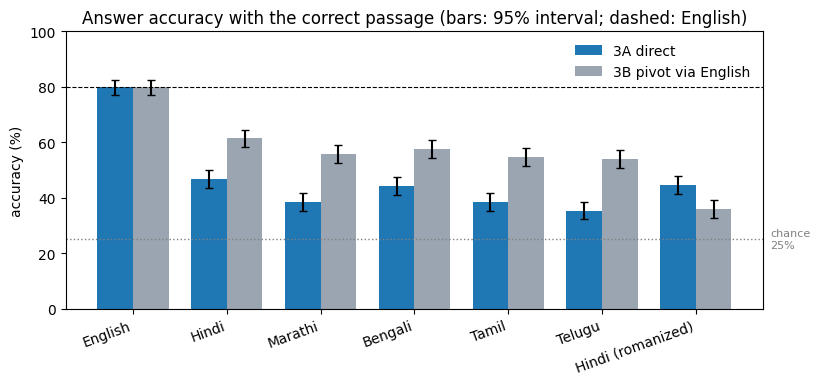

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(EVAL_LANGS))
for i, (setting, label, color) in enumerate([("direct_gold", "3A direct", "#1f77b4"), ("pivot_gold", "3B pivot via English", "#9aa5b1")]):
    vals = [acc(setting, l) for l in EVAL_LANGS]
    ci = np.array([wilson(RESULTS[(setting, l)]["correct"].to_numpy()) for l in EVAL_LANGS])
    err = np.vstack([np.array(vals) - ci[:, 0], ci[:, 1] - np.array(vals)])
    ax.bar(x + (i - 0.5) * 0.38, vals, 0.38, yerr=err, capsize=3, color=color, label=label)
ax.axhline(25, color="grey", ls=":", lw=1)
ax.text(1.01, 25, "chance\n25%", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="grey")
ax.axhline(acc("direct_gold", BASELINE), color="black", ls="--", lw=0.8)
ax.set_xticks(x, [name(l) for l in EVAL_LANGS], rotation=20, ha="right")
ax.set_ylim(0, 100); ax.set_ylabel("accuracy (%)")
ax.set_title("Answer accuracy with the correct passage (bars: 95% interval; dashed: English)")
ax.legend(frameon=False, loc="upper right")
save_fig(fig, "4_answer_accuracy.png")

### 12.2 Paired comparison: which questions flip?

Every question exists in English and in the test language. So we can count, question by question:

- **both right**, **both wrong**: the language changed nothing.
- **only English right**: a **drop** caused by the language.
- **only this language right**: the language helped (usually luck).

**McNemar test.** If language had no effect, drops and gains would be equally likely, like coin flips. The test asks: how surprising is the split we see between drops and gains? A small *p* (below 0.05) means the drop is real, not noise. Only the questions that flipped matter for this test.

In [23]:
def paired(res_a, res_b):
    a, b = res_a["correct"], res_b["correct"]
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return {"both right": int((a & b).sum()), "both wrong": int((~a & ~b).sum()),
            "only first right": only_a, "only second right": only_b, "McNemar p": p}

eng = RESULTS[("direct_gold", BASELINE)]
flips = pd.DataFrame({name(l): paired(eng, RESULTS[("direct_gold", l)]) for l in EVAL_LANGS if l != BASELINE}).T
flips = flips.rename(columns={"only first right": "only English right (drop)", "only second right": "only this language right"})
pivot_vs_direct = pd.DataFrame({name(l): paired(RESULTS[("pivot_gold", l)], RESULTS[("direct_gold", l)])
                                for l in EVAL_LANGS if l != BASELINE}).T
pivot_vs_direct = pivot_vs_direct.rename(columns={"only first right": "fixed by translation", "only second right": "broken by translation"})
for table in (flips, pivot_vs_direct):
    counts = [c for c in table.columns if c != "McNemar p"]
    table[counts] = table[counts].astype(int)
    table["McNemar p"] = table["McNemar p"].astype(float).map(lambda v: f"{v:.2g}")
print("English vs each language (3A direct, correct passage):"); display(flips)
print("Pivot vs direct, same language (does translation help?):"); display(pivot_vs_direct)

English vs each language (3A direct, correct passage):


,both right,both wrong,only English right (drop),only this language right,McNemar p
Hindi,383,143,335,39,8.1e-60
Marathi,305,141,413,41,1.9e-78
Bengali,352,135,366,47,2.5e-62
Tamil,307,144,411,38,3.5e-80
Telugu,280,144,438,38,2.6e-87
Hindi (romanized),364,145,354,37,4.5e-66


Pivot vs direct, same language (does translation help?):


,both right,both wrong,fixed by translation,broken by translation,McNemar p
Hindi,336,261,217,86,3.2e-14
Marathi,230,283,271,116,2.1e-15
Bengali,287,271,230,112,1.7e-10
Tamil,241,303,252,104,2.6e-15
Telugu,208,303,279,110,4.8e-18
Hindi (romanized),239,415,84,162,7.5e-07


### 12.3 The drop map

Each cell is *this language minus English* in percentage points, for one stage. Red = a loss. Read across a row to find the stage where a language loses most.

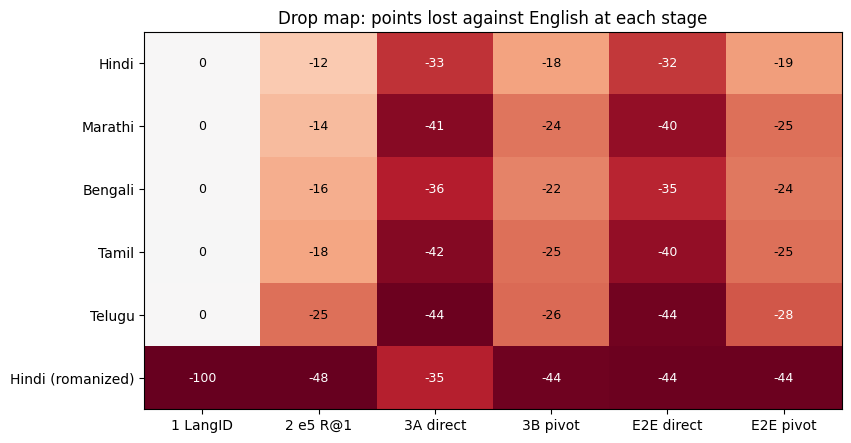

In [24]:
stage_cols = ["1 LangID (%)", "2 e5 R@1 (%)", "3A direct (%)", "3B pivot (%)", "E2E direct (%)", "E2E pivot (%)"]
drop_map = summary[stage_cols].sub(summary.loc[name(BASELINE), stage_cols], axis=1).drop(index=name(BASELINE))

fig, ax = plt.subplots(figsize=(9, 0.55 * len(drop_map) + 1.6))
lim = float(np.clip(np.nanpercentile(np.abs(drop_map.values), 95), 10, 100))   # scale from typical drops, not one outlier
ax.imshow(drop_map.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(stage_cols)), [c.replace(" (%)", "") for c in stage_cols])
ax.set_yticks(range(len(drop_map)), drop_map.index)
for i in range(drop_map.shape[0]):
    for j in range(drop_map.shape[1]):
        v = drop_map.values[i, j]
        label = "0" if abs(v) < 0.5 else f"{v:+.0f}"          # no "-0"
        ax.text(j, i, label, ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 * lim else "black")
ax.set_title("Drop map: points lost against English at each stage")
save_fig(fig, "5_drop_map.png")

### 12.4 Where each language loses its questions (end to end, direct route)

Every wrong end-to-end answer gets **one** cause, checked in pipeline order:

1. **language ID** — the predicted language was wrong;
2. **retrieval** — else, the top passage was not the right one;
3. **reading** — else, the model had the right passage and still chose wrongly.

,correct,lost at language ID,lost at retrieval,lost at reading
English,76.7,0.0,5.7,17.7
Hindi,44.7,0.0,14.6,40.8
Marathi,37.0,0.1,16.7,46.2
Bengali,42.1,0.1,16.9,40.9
Tamil,37.0,0.0,18.7,44.3
Telugu,33.0,0.0,24.8,42.2
Hindi (romanized),32.4,67.6,0.0,0.0


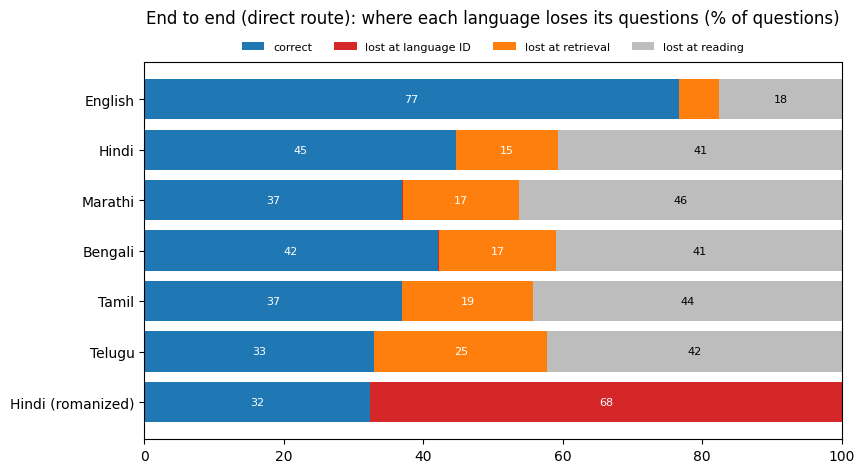

In [25]:
def e2e_cause(lang, setting):
    res, info = RESULTS[(setting, lang)], E2E_INFO[lang]
    cause = pd.Series("correct", index=res.index)
    wrong = ~res["correct"]
    cause[wrong & ~info["lid_ok"]] = "lost at language ID"
    cause[wrong & info["lid_ok"] & ~info["retrieval_ok"]] = "lost at retrieval"
    cause[wrong & info["lid_ok"] & info["retrieval_ok"]] = "lost at reading"
    return cause

CAUSES = ["correct", "lost at language ID", "lost at retrieval", "lost at reading"]
loss = pd.DataFrame({name(l): e2e_cause(l, DIRECT_E2E).value_counts(normalize=True).reindex(CAUSES, fill_value=0) * 100
                     for l in EVAL_LANGS}).T.round(1)
display(loss)

fig, ax = plt.subplots(figsize=(9, 0.5 * len(loss) + 1.4))
colors = {"correct": "#1f77b4", "lost at language ID": "#d62728", "lost at retrieval": "#ff7f0e", "lost at reading": "#bdbdbd"}
left = np.zeros(len(loss))
for c in CAUSES:
    ax.barh(loss.index, loss[c], left=left, color=colors[c], label=c)
    for i, (l, v) in enumerate(zip(left, loss[c])):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if c != "lost at reading" else "black")
    left += loss[c].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_title("End to end (direct route): where each language loses its questions (% of questions)", pad=28)
ax.legend(ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0), loc="lower center", fontsize=8)
save_fig(fig, "6_e2e_losses.png")

## 13. Failure examples

We look at the **drops** of Section 12.2: questions that English answers correctly but this language does not (direct route, correct passage). Each drop gets a category:

| Category | Rule |
|---|---|
| fixed by translation | the pivot route answers it correctly |
| translation damaged the passage | the pivot route is also wrong, and the passage chrF is below `CHRF_DAMAGED` |
| hard even after translation | the pivot route is also wrong, and the translation looks fine |

We also mark questions whose correct option contains a **number**. Numbers can be written in native digits (for example `४३६` or `৪৩৬`), and tokenizers often cut them badly.

The English text in brackets is the real Belebele English version of the same option. It lets you read every failure without knowing the language.

In [26]:
def has_number(text):
    return any(ch.isdigit() for ch in text)          # also true for Devanagari, Bengali, Tamil digits

def drop_category(lang, qid):
    if RESULTS[("pivot_gold", lang)].loc[qid, "correct"]:
        return "fixed by translation"
    if PIVOT[lang].loc[qid, "chrf_passage"] < CHRF_DAMAGED:
        return "translation damaged the passage"
    return "hard even after translation"

rng = np.random.default_rng(SEED)
eng = RESULTS[("direct_gold", BASELINE)]
category_counts, examples = {}, []
for lang in EVAL_LANGS:
    if lang == BASELINE:
        continue
    d = RESULTS[("direct_gold", lang)]
    drops = d.index[eng["correct"].to_numpy() & ~d["correct"].to_numpy()]
    cats = pd.Series([drop_category(lang, q) for q in drops], index=drops, dtype=object)
    category_counts[name(lang)] = cats.value_counts().to_dict() | {"total drops": len(drops)}
    picks = rng.choice(drops, size=min(N_FAILURE_EXAMPLES, len(drops)), replace=False) if len(drops) else []
    for q in picks:
        b, e = B[lang].loc[q], B[BASELINE].loc[q]
        pred, gold = int(d.loc[q, "pred"]), int(b["answer"])
        examples.append({
            "language": name(lang), "qid": int(q), "category": cats[q],
            "number in answer": has_number(b["options"][gold]),
            "question": b["question"], "English original": e["question"],
            "NLLB translation": PIVOT[lang].loc[q, "question"],
            "correct option": f"{LETTERS[gold]}. {b['options'][gold]}  [{e['options'][gold]}]",
            "model chose": f"{LETTERS[pred]}. {b['options'][pred]}  [{e['options'][pred]}]",
            "confidence": round(float(d.loc[q, "conf"]), 2),
            "passage chrF": round(float(PIVOT[lang].loc[q, "chrf_passage"]), 1),
        })

column_order = ["fixed by translation", "translation damaged the passage", "hard even after translation", "total drops"]
drop_categories = pd.DataFrame(category_counts).T.reindex(columns=column_order).fillna(0).astype(int)
drop_categories.index.name = "language"
failures = pd.DataFrame(examples)
display(drop_categories)
failures

,fixed by translation,translation damaged the passage,hard even after translation,total drops
language,,,,
Hindi,198,0,137,335
Marathi,249,0,164,413
Bengali,213,2,151,366
Tamil,238,0,173,411
Telugu,252,1,185,438
Hindi (romanized),68,285,1,354


,language,qid,category,number in answer,question,English original,NLLB translation,correct option,model chose,confidence,passage chrF
0,Hindi,708,fixed by translation,False,निम्नलिखित में से कौन सा दावे यह तथ्य है कि फ़ॉकलैंड्स में मुद्रा का उपयोग?,"Regarding the use of currency in the Falklands, which of the following statements is true?",Which of the following claims is the fact that currency use in the Falkland Islands?,"D. फ़ॉकलैंड पाउंड के अलावा, ब्रिटिश पाउंड आम तौर पर सबसे अधिक स्वीकृत मुद्रा है [Aside from the Falkland pound, the British pound is ge...",A. बाहरी द्वीपों पर केवल क्रेडिट कार्ड और ब्रिटिश पाउंड स्वीकार किए जाते हैं [Only credit cards and British pounds are accepted on the ...,0.99,69.9
1,Hindi,415,fixed by translation,False,"परिच्छेद के अनुसार, निम्नलिखित में से किस पर अंग्रेज़ शिक्षक कार्नो का आरोप नहीं था?","According to the passage, which of the following was the English tutor Karno not accused of?","According to the paragraph, which of the following was not the fault of the English teacher Carno?",B. एक छात्र के साथ डेटिंग [Dating a student],C. अनधिकृत विज्ञापन प्रिंट करना [Printing unauthorized advertisements],0.74,58.5
2,Hindi,604,fixed by translation,False,CEP के इस्तीफे की सिफारिश करने वाला कौन था?,Who suggested that the last CEP resign?,Who was the one who recommended the resignation of CEP?,C. राष्ट्रपति आयोग [The presidential commission],A. मार्टली [Martelly],1.00,65.7
3,Hindi,78,hard even after translation,False,प्रयोग का सामान्य उद्देश्य क्या है?,Which is the typical purpose of an experiment?,What is the general purpose of the experiment?,A. यह एक या अधिक संभावित परिकल्पनाओं की अस्वीकृति है [To eliminate one or more possible hypotheses],B. जब आपको पता चलता है कि दुनिया कैसे काम करती है [To figure out how the world works],1.00,62.9
4,Hindi,413,hard even after translation,False,संदिग्ध अपराधी की जांच किस लिए की जा रही है?,What is the suspected offender being investigated for?,For what is the suspect being investigated?,A. अनधिकार [Trespassing],B. शारीरिक क्षति [Physical damage],0.98,68.2
5,Marathi,878,hard even after translation,False,खालीलपैकी कोणत्या ठिकणी पर्यटक त्यांची नोंदणी करू शकत नाही?,Which of the following is not a place a tourist might go to handle their registration?,Which of the following destinations cannot be registered by tourists?,C. स्थानिक पोस्ट ऑफिस [A local post office],B. ते ज्या हॉटेलमध्ये राहतात [The hotel at which they’re staying],1.00,70.1
6,Marathi,98,fixed by translation,False,"परिच्छेदात सादर केलेल्या सिद्धांतानुसार, वांशिक अल्पसंख्याक असलेल्या मुलाचे काय होऊ शकते जो घातक रुढीवादाला बळी पडला असेल?","According to the theory presented in the passage, what might happen to a child who identifies with a racial minority that is stereotyped...","According to the theory presented in the paragraph, what could happen to a child with an ethnic minority who has been a victim of deadly...",B. मुल धोकादायक वर्तनात गुंतण्याची अधिक शक्यता असते [The child will be more likely to engage in menacing behavior],C. मुल धोकादायक वागणुकीत गुंतण्याची अधिक शक्यता असते [The child will withdraw in social situations],0.79,41.1
7,Marathi,483,fixed by translation,True,नदाल आणि राओनिक यांच्यातील सामन्यात पहिल्या सर्व्हनंतर काय स्थिती होती?,"According to the passage, what was the standing of Nadal and Raonic’s match after the first serve?",What was the status of the match between Nadal and Raonic after the first service?,B. नदालने 76 पॉइंट्स जिंकले [Nadal won 76 points],A. राओनिककडे 88% नेट पॉइंट्स होते [Raonic had 88% net points],0.98,66.5
8,Marathi,705,hard even after translation,False,इक्वाडोरच्या प्रवास आवश्यकता कशासाठी तयार केलेल्या नाहीत?,What are Ecuador’s travel requirements not designed for?,Why are Ecuador's travel requirements not designed for?,A. प्रवाशांची संख्या कमीत कमी ठेवणे [Keeping the number of travelers to a minimum],C. प्रवाशाच्या वास्तव्याच्या कालावधीची पुष्टी करणे [Confirming a traveler’s length of stay],0.93,66.6
9,Marathi,684,fixed by translation,False,यांपैकी काय हिवाळ्यात 

## 14. Two diagnostics

**Token tax against the drop.** Does a language lose more accuracy when the LLM needs more tokens for it? With only 6 languages this is a hint, not a proof: other things also differ between languages, such as how much training text the model saw.

**Number questions.** Accuracy on questions whose correct option contains a number, against all other questions.

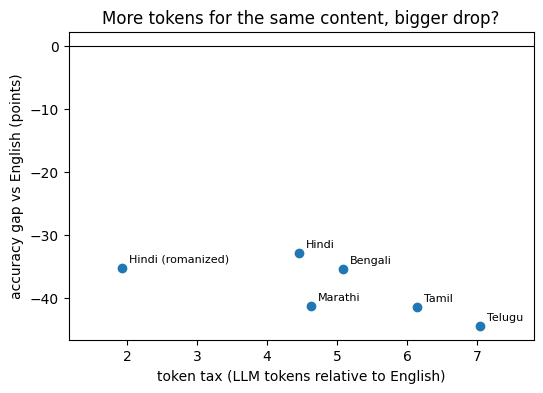

Pearson r, all variants: -0.69
Pearson r, native scripts only: -0.76


,number questions,"accuracy, number questions (%)","accuracy, other questions (%)"
English,52,69.2,80.4
Hindi,52,42.3,47.2
Marathi,52,42.3,38.2
Bengali,52,48.1,44.1
Tamil,52,42.3,38.1
Telugu,52,44.2,34.8
Hindi (romanized),52,40.4,44.8


In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
others = [l for l in EVAL_LANGS if l != BASELINE]
xs = [token_tax.loc[name(l), "LLM"] for l in others]
ys = [summary.loc[name(l), "gap 3A vs EN"] for l in others]
ax.scatter(xs, ys, color="#1f77b4")
for x_, y_, l in zip(xs, ys, others):
    ax.annotate(name(l), (x_, y_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.margins(x=0.15)                                        # keep edge labels inside the frame
ax.set_xlabel("token tax (LLM tokens relative to English)")
ax.set_ylabel("accuracy gap vs English (points)")
ax.set_title("More tokens for the same content, bigger drop?")
save_fig(fig, "7_token_tax_vs_gap.png")
native = [i for i, l in enumerate(others) if l == nllb_code(l)]          # leave out romanized variants
for label, idx in [("all variants", list(range(len(xs)))), ("native scripts only", native)]:
    if len(idx) > 2:
        print(f"Pearson r, {label}: {np.corrcoef([xs[i] for i in idx], [ys[i] for i in idx])[0, 1]:.2f}")

num_mask = {l: B[l].apply(lambda r: has_number(r["options"][r["answer"]]), axis=1) for l in EVAL_LANGS}
numbers = pd.DataFrame({name(l): {
    "number questions": int(num_mask[BASELINE].sum()),
    "accuracy, number questions (%)": 100 * RESULTS[("direct_gold", l)]["correct"][num_mask[BASELINE].to_numpy()].mean(),
    "accuracy, other questions (%)": 100 * RESULTS[("direct_gold", l)]["correct"][~num_mask[BASELINE].to_numpy()].mean(),
} for l in EVAL_LANGS}).T.round(1)
numbers["number questions"] = numbers["number questions"].astype(int)
numbers

## 15. Write the report

This cell writes the deliverable to `bhashacore_outputs/`:

- `report.md` — the comparison report: tables, charts, failure categories and examples;
- `summary.csv` — the summary table;
- `per_question.csv` — every prediction (language, question, setting, chosen option, right or wrong);
- `failures.csv` — the failure examples;
- `figures/*.png` — all charts.

Open `report.md` in VS Code (Ctrl+Shift+V) or on GitHub to see it with the charts.

In [28]:
summary.to_csv(OUT_DIR / "summary.csv")
failures.to_csv(OUT_DIR / "failures.csv", index=False)
pd.concat([res.assign(language=lang, setting=setting) for (setting, lang), res in RESULTS.items()]) \
  .reset_index().to_csv(OUT_DIR / "per_question.csv", index=False)

worst = summary.drop(index=name(BASELINE))["gap 3A vs EN"].idxmin()
best_pivot = (summary["3B pivot (%)"] - summary["3A direct (%)"]).drop(index=name(BASELINE))
report = [
    "# BhashaCore comparison report", "",
    f"Generated {pd.Timestamp.now():%Y-%m-%d %H:%M} · {len(qids)} paired Belebele questions per language · "
    f"LLM `{LLM_NAME}` · translator `{MT_NAME}` · retriever `{EMB_NAME}` · end-to-end retriever `{E2E_RETRIEVER}`", "",
    "## Headline", "",
    f"- English accuracy with the correct passage: **{acc('direct_gold', BASELINE):.1f}%** (chance = 25%).",
    f"- Largest drop: **{worst}**, {summary.loc[worst, 'gap 3A vs EN']:+.1f} points against English.",
    f"- Translation to English helps most for **{best_pivot.idxmax()}** ({best_pivot.max():+.1f} points) "
    f"and least for **{best_pivot.idxmin()}** ({best_pivot.min():+.1f} points).", "",
    "## 1. Summary by stage", "", md_table(summary), "",
    "Columns: language-ID accuracy on questions; Recall@1 of each retriever; chrF of NLLB's English against the real English passage; "
    "answer accuracy with the correct passage (3A direct, 3B pivot); end-to-end accuracy; gap = language minus English (points); "
    "token tax = LLM tokens relative to English.", "",
    "![answer accuracy](figures/4_answer_accuracy.png)", "",
    "## 2. Drop map", "", "![drop map](figures/5_drop_map.png)", "",
    "## 3. Where questions are lost end to end (direct route)", "", md_table(loss), "", "![losses](figures/6_e2e_losses.png)", "",
    "## 4. Paired flips against English (3A direct, correct passage)", "", md_table(flips), "",
    "## 5. Does translation help? (pivot vs direct, same language)", "", md_table(pivot_vs_direct), "",
    "## 6. Language identification", "", md_table(lid_short_df), "", "![confusion](figures/1_langid_confusion.png)", "",
    "## 7. Retrieval", "", "![retrieval](figures/3_retrieval.png)", "",
    "## 8. Token tax", "", md_table(token_tax, 2), "", "![token tax](figures/2_token_tax.png)", "",
    "![token tax vs gap](figures/7_token_tax_vs_gap.png)", "",
    "## 9. Number questions", "", md_table(numbers), "",
    "## 10. Why answers dropped (questions English got right)", "", md_table(drop_categories, 0), "",
    "## 11. Failure examples", "",
    "Text in [brackets] is the real English version of the same option.", "",
]
for lang_name, group in failures.groupby("language", sort=False):
    report += [f"### {lang_name}", ""]
    for _, r in group.iterrows():
        report += [f"- **qid {r['qid']}** · {r['category']}{' · number in answer' if r['number in answer'] else ''} · confidence {r['confidence']}",
                   f"  - Question: {r['question']}", f"  - English original: {r['English original']}",
                   f"  - NLLB translation: {r['NLLB translation']}",
                   f"  - Correct: {r['correct option']}", f"  - Model chose: {r['model chose']}", ""]
report += ["## Limits", "",
           "- Belebele passages are news text, not government FAQs; the method transfers, the numbers may not.",
           "- One LLM and one prompt; another model or a native-language instruction can change the ranking.",
           "- Failure categories come from simple rules. Read the examples before you trust a count.",
           "- Intervals are 95% Wilson intervals; McNemar p-values compare paired questions."]
(OUT_DIR / "report.md").write_text("\n".join(report), encoding="utf-8")
print("wrote", OUT_DIR / "report.md")

wrote bhashacore_outputs/report.md


## 16. Chatbot demo — free-text answers

Until now the model chose A–D. A real chatbot writes an answer. This function runs the full pipeline on any message, with no options:

- **direct**: detect the language → search that language's knowledge base → the LLM answers in that language.
- **pivot**: detect the language → translate the question to English → search the English knowledge base → the LLM answers in English → translate the answer back.

Try your own questions in the last cell. The knowledge base holds only the Belebele news passages, so ask about their topics.

In [29]:
@torch.no_grad()
def generate(prompt_text, max_new_tokens=256):          # Indian scripts need ~4-7x more tokens than English
    enc = llm_tok(prompt_text, return_tensors="pt", add_special_tokens=not USE_CHAT).to(DEVICE)
    out = llm.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                       max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=llm_tok.pad_token_id)
    return llm_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def chat_prompt(passage, question, reply_language):
    return wrap(f"Passage:\n{passage}\n\nQuestion: {question}\n\n"
                f"Answer in {reply_language}, in one or two sentences, using only the passage.")

def bhashacore_chat(message, route="direct"):
    lang = LID_LANGS[lid.predict([message])[0]]
    if route == "direct":
        kb_lang = lang if lang in KB else BASELINE
        pid = retrieve(E2E_RETRIEVER, kb_lang, [message], k=1)[0, 0]
        answer = generate(chat_prompt(KB[kb_lang].loc[pid], message, name(lang)))
    else:
        question_en = translate([message], nllb_code(lang))[0]
        pid = retrieve(E2E_RETRIEVER, BASELINE, [question_en], k=1)[0, 0]
        answer_en = generate(chat_prompt(KB[BASELINE].loc[pid], question_en, "English"))
        answer = translate([answer_en], BASELINE, nllb_code(lang))[0]
    return {"detected language": name(lang), "passage id": int(pid), "answer": answer}

In [30]:
q = qids[1]
demo_rows = []
for lang in [l for l in ["hin_Deva", "tam_Taml", "hin_Latn"] if l in EVAL_LANGS]:
    message = B[lang].loc[q, "question"]
    for route in ("direct", "pivot"):
        out = bhashacore_chat(message, route)
        demo_rows.append({"language": name(lang), "route": route, "message": message, **out,
                          "right passage": out["passage id"] == B[lang].loc[q, "pid"]})
print("English question:", B[BASELINE].loc[q, "question"])
print("Correct option   :", B[BASELINE].loc[q, "options"][B[BASELINE].loc[q, "answer"]])
pd.DataFrame(demo_rows)

English question: When playing the accordion, which of the following will help to increase the volume?
Correct option   : More speed


,language,route,message,detected language,passage id,answer,right passage
0,Hindi,direct,"अक्कडियन को पुनः प्राप्त करते समय, निम्न में से कौन सा आयतन बढ़ाता है?",Hindi,374,"अक्कडियन को पुनः प्राप्त करते समय, इसमें से किस आयतन बढ़ाता है? अपने दौर में जल्दी ही आता है, लेकिन ऐसा लंबे समय तक रहता है और अधिक गंभी...",False
1,Hindi,pivot,"अक्कडियन को पुनः प्राप्त करते समय, निम्न में से कौन सा आयतन बढ़ाता है?",Hindi,269,इस भाग में अकडियन को बहाल करने के दौरान मात्रा में वृद्धि करने के बारे में कोई जानकारी नहीं दी गई है।,False
2,Tamil,direct,"சுரங்களை வாசிக்கும் போது, பின்வருவனவற்றுல் சத்தத்தை அதிகரிப்பது எது?",Tamil,0,"ஒரு சுரங்களை வாசிக்கும் போது, பின்வருவனவற்றுல் சத்தத்தை அதிகரிப்பது முடிந்த அளவு குறைவாக சோர்வடைவீர்கள்.",True
3,Tamil,pivot,"சுரங்களை வாசிக்கும் போது, பின்வருவனவற்றுல் சத்தத்தை அதிகரிப்பது எது?",Tamil,13,"இந்த பகுதி, எழுத்துக்கள் வாசிக்கும் போது அளவை அதிகரிப்பது குறித்து எந்த தகவலும் அளிக்கவில்லை.",False
4,Hindi (romanized),direct,"Accordion bajate hue, inmein se kya volume ko badhane mein madad karega?",English,0,"On the accordion, to get extra volume, you use the bellows with more pressure or speed.",True
5,Hindi (romanized),pivot,"Accordion bajate hue, inmein se kya volume ko badhane mein madad karega?",English,0,"On the accordion, to get extra volume, you use the bellows with more pressure or speed.",True


In [31]:
# Your turn: type any question in any language
bhashacore_chat("बिजली बिल की शिकायत कहाँ करें?", route="pivot")

{'detected language': 'Hindi',
 'passage id': 39,
 'answer': 'इस खंड में बिजली बिलों के बारे में शिकायत करने का कोई उल्लेख नहीं है। यह परिवहन प्रणालियों पर चर्चा करता है लेकिन यह निर्दिष्ट नहीं करता है कि लोग बिजली बिलों के बारे में कहां शिकायत कर सकते हैं।'}

## 17. Next steps

- **Bigger LLM.** Set `LLM_NAME = "Qwen/Qwen2.5-7B-Instruct"` on the A30. Does the gap shrink, or does every language rise together?
- **Better translator.** Replace NLLB with AI4Bharat's IndicTrans2 (made for Indian languages). Does the pivot route improve for Tamil and Telugu?
- **Romanized input.** Add romanized sentences to the language identifier, for example by transliterating IndicCorp lines with a library such as `indic-transliteration`. Does the end-to-end score for romanized Hindi rise?
- **Native instructions.** Write the prompt instruction in Hindi for the Hindi run. Does the score change?
- **Government text.** Replace the Belebele passages with real government FAQ pages in several languages. Keep the same pipeline and metrics.